In [1]:
# source .venv-data/bin/activate
#!pip install pyarrow==25.0.1
#!pip install lseg-data==2.1.1
#!pip install matplotlib==3.11.1
#!pip install statsmodels==0.15.0

In [2]:
import io
import copy
import time
import zipfile
import numpy as np
import pandas as pd
import lseg.data as ld
from pathlib import Path
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from urllib.request import urlopen
from statsmodels.regression.rolling import RollingOLS

In [3]:
# paleta de colores
PRINCIPAL = "#940028"
BLANCO = "#FFFFFF"
GRIS = "#D9D9D9"
NEGRO = "#000000"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "figure.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "legend.title_fontsize": 11,
    "figure.facecolor": BLANCO,
    "axes.facecolor": BLANCO,
    "text.color": NEGRO,
    "axes.labelcolor": NEGRO,
    "xtick.color": NEGRO,
    "ytick.color": NEGRO,
    "lines.linewidth": 1.6,
    "savefig.dpi": 300,
    "savefig.facecolor": BLANCO,
})

In [4]:
# carpeta para guardar las figuras generadas
carpeta_figuras = Path("outputs/figures")
carpeta_figuras.mkdir(parents=True, exist_ok=True)

# carpeta para guardar miembros historicos
carpeta_miembros = Path("outputs/constituents")
carpeta_miembros.mkdir(parents=True, exist_ok=True)

# carpeta para guardar el precio de los activos
carpeta_acciones = Path("outputs/equity")
carpeta_acciones.mkdir(parents=True, exist_ok=True)

# carpeta de factores
carpeta_factores = Path("outputs/factors")
carpeta_factores.mkdir(parents=True, exist_ok=True)

# carpeta con resultados de las regresiones
carpeta_regresiones = Path("outputs/regressions")
carpeta_regresiones.mkdir(parents=True, exist_ok=True)

In [5]:
class IndexConstituents:

    def get_historical_constituents(self, index, start, end):
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        if pd.isna(start) or pd.isna(end) or start > end:
            raise ValueError('Se requieren fechas válidas con start <= end')
        start, end = start.normalize(), end.normalize()
        final_date, constituents = self._get_snapshot(index, end)
        if final_date < start:
            raise ValueError('El snapshot disponible es anterior a start')
        changes = self.get_constituent_changes(index, start.date(), final_date.date())
        print("Fechas de cambios:", changes['Date'].nunique())
        return self.update_constituents(start, final_date, constituents, changes)

    def get_constituents_as_of(self, ric, date):
        return self._get_snapshot(ric, date)[1]

    def _get_snapshot(self, ric, date):
        date = pd.Timestamp(date)
        if pd.isna(date):
            raise ValueError('Se requiere una fecha válida')
        date = date.normalize()
        for days in range(11):
            effective = date - pd.Timedelta(days, unit='D')
            data = ld.get_data(universe=[ric], fields=['TR.IndexConstituentRIC'],
                               parameters={'SDate': str(effective.date())})
            if 'Constituent RIC' not in data.columns:
                raise ValueError('Falta la columna Constituent RIC en el snapshot')
            members = sorted(set(data['Constituent RIC'].dropna()) - {''})
            if members:
                return effective, members
        raise ValueError(f'No hay snapshot de {ric} en los 10 días anteriores a {date.date()}')

    def get_constituent_changes(self, ric, start, end):
        const_changes  = ld.get_data(universe=[ric], 
                    fields = ["TR.IndexJLConstituentChangeDate", "TR.IndexJLConstituentRIC",
                            "TR.IndexJLConstituentName", "TR.IndexJLConstituentituentChange"],
                    parameters={"SDATE":f"{start}","EDATE":f"{end}", 'IC':'B'}
                )
        return const_changes

    def update_constituents(self, start, end, constituents, constituent_changes):
        required = ['Date', 'Change', 'Constituent RIC']
        if not set(required).issubset(constituent_changes.columns):
            raise ValueError(f'Los cambios requieren las columnas {required}')
        changes = constituent_changes.dropna(subset=required, how='all')
        changes = changes.assign(Date=pd.to_datetime(changes['Date']).dt.normalize())
        if changes[required].isna().any().any():
            raise ValueError('Hay cambios con fecha, tipo o RIC faltante')
        changes = changes.loc[(changes['Date'] > start) & (changes['Date'] <= end)]
        if not changes['Change'].isin(['Joiner', 'Leaver']).all():
            raise ValueError('Tipo de cambio distinto de Joiner/Leaver')
        members = set(constituents)
        # etiquetar el cierre con la fecha efectiva
        rows = [(end, ric) for ric in members]
        for date, events in changes.sort_values('Date', ascending=False).groupby('Date', sort=False):
            rows.extend((date, ric) for ric in members)  # estado posterior al cambio
            joiners = set(events.loc[events['Change'].eq('Joiner'), 'Constituent RIC'])
            leavers = set(events.loc[events['Change'].eq('Leaver'), 'Constituent RIC'])
            members.difference_update(joiners - leavers)
            members.update(leavers - joiners)
        rows.extend((start, ric) for ric in members)
        return (pd.DataFrame(rows, columns=['Date', 'RIC']).drop_duplicates()
                .sort_values(['Date', 'RIC']).reset_index(drop=True))


Fechas de cambios: 758
Snapshots: 758


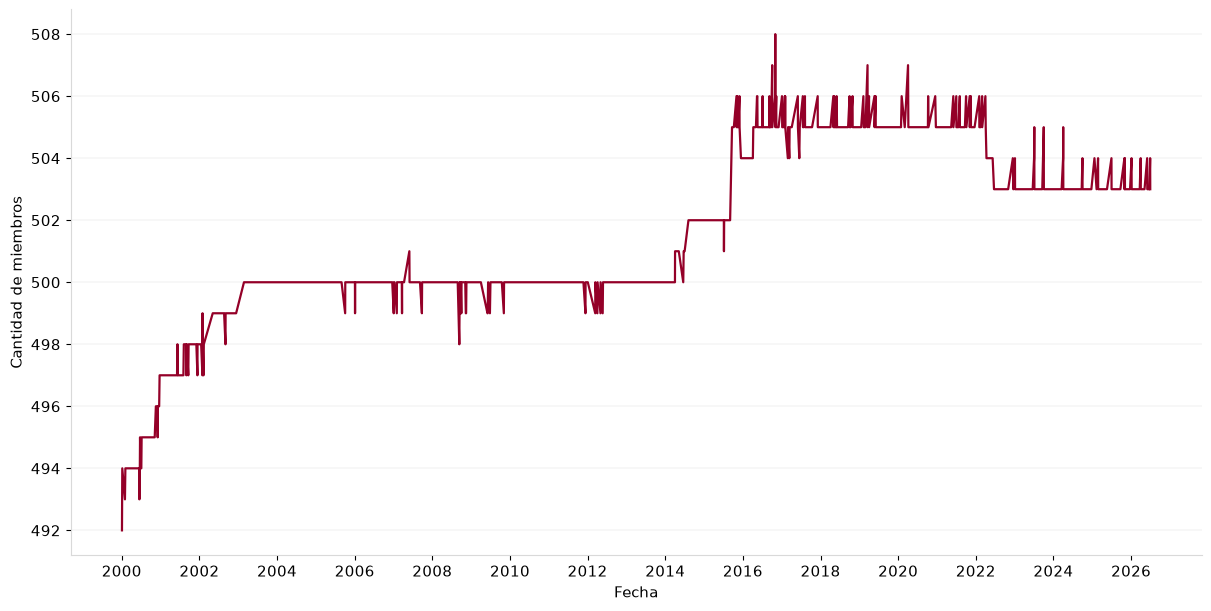

In [6]:
ld.open_session() # abrimos la sesion

ic = IndexConstituents() # instanciamos la clase

# obtenemos los miembros historicos
spx_constituents = ic.get_historical_constituents(
    index= '.SPX', start = '1960-01-01', end = '2026-06-30')
print("Snapshots:", spx_constituents['Date'].nunique())

# filtramos y graficamos
spx_constituents = spx_constituents[spx_constituents["Date"]>=pd.Timestamp('2000-01-01')]
daily_grouped = spx_constituents.groupby(by = ["Date"]).count()
daily_grouped.index = pd.to_datetime(daily_grouped.index)
daily_grouped = daily_grouped.sort_index()

fig, ax = plt.subplots(
    figsize=(12, 6),
    facecolor=BLANCO,
    constrained_layout=True,
)

ax.plot(
    daily_grouped.index,
    daily_grouped["RIC"],
    color=PRINCIPAL,
    linewidth=1.6,
)

ax.set_xlabel("Fecha", color=NEGRO)
ax.set_ylabel("Cantidad de miembros", color=NEGRO)

ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.set_facecolor(BLANCO)
ax.grid(axis="y", color=GRIS, linewidth=0.3)
ax.grid(axis="x", visible=False)
ax.tick_params(axis="both", colors=NEGRO, labelsize=11)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color(GRIS)
ax.spines["bottom"].set_color(GRIS)

fig.savefig(
    carpeta_figuras / "rics-per-day-spx.png",
    dpi=300,
    facecolor=BLANCO,
)

plt.show()
plt.close(fig)

In [7]:
print("Snapshots:", spx_constituents['Date'].nunique()) # despues de filtrar
filepath = carpeta_miembros / "spx_constituents.parquet"
if not filepath.exists():
    spx_constituents.to_parquet(filepath)

Snapshots: 602


In [8]:
failures = []

for ric in spx_constituents.RIC.unique():
    filename = f"{ric.replace('/', '_')}.parquet"
    filepath = carpeta_acciones / filename

    # saltar activos ya descargados
    if filepath.exists():
        continue

    try:
        prices = ld.get_history(
            universe=[ric],
            fields=['TR.OPENPRICE', 'TR.CLOSEPRICE', 'TR.TSVWAP', 'TR.TotalReturn'],
            interval='daily',
            start='2000-01-01',
            end='2026-06-30',
            count=10000
        )

        if prices is None or prices.empty:
            failures.append((ric, 'Sin datos'))
        else:
            for column in prices.columns:
                if prices[column].dtype == 'object':
                    prices[column] = pd.to_numeric(
                        prices[column],
                        errors='coerce'
                    )
            prices.to_parquet(filepath)

    except Exception as error:
        failures.append((ric, str(error)))

    time.sleep(0.2)

In [9]:
len(failures)

3

In [10]:
failures

[('FSR.N^B01',
  "Unable to collect data for the field 'TR.OPENPRICE' and some specific identifier(s). Requested universes: ['FSR.N^B01']. Requested fields: ['TR.OPENPRICE', 'TR.CLOSEPRICE', 'TR.TSVWAP', 'TR.TOTALRETURN']"),
 ('GX.N^A02', 'Sin datos'),
 ('FLR_w.N^L00',
  "Unable to collect data for the field 'TR.OPENPRICE' and some specific identifier(s). Requested universes: ['FLR_w.N^L00']. Requested fields: ['TR.OPENPRICE', 'TR.CLOSEPRICE', 'TR.TSVWAP', 'TR.TOTALRETURN']")]

In [11]:
# descargamos los factores ff3
url = (
    "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_daily_CSV.zip"
)
archivo_parquet = carpeta_factores / "fama_french_3_daily.parquet"
with urlopen(url, timeout=60) as response:
    zip_content = response.read()
with zipfile.ZipFile(io.BytesIO(zip_content)) as archive:
    csv_name = next(
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
    )

    csv_content = archive.read(csv_name).decode(
        "utf-8",
        errors="replace"
    )
lines = csv_content.splitlines()
header_position = next(
    position
    for position, line in enumerate(lines)
    if "Mkt-RF" in line and "SMB" in line and "HML" in line
)
fama_french = pd.read_csv(
    io.StringIO("\n".join(lines[header_position:]))
)
fama_french = fama_french.rename(
    columns={fama_french.columns[0]: "Date"}
)
date_text = fama_french["Date"].astype(str).str.strip()
fama_french = fama_french.loc[
    date_text.str.fullmatch(r"\d{8}")
].copy()
fama_french["Date"] = pd.to_datetime(
    fama_french["Date"].astype(str),
    format="%Y%m%d"
)
factor_columns = ["Mkt-RF", "SMB", "HML", "RF"]
fama_french[factor_columns] = (
    fama_french[factor_columns]
    .apply(pd.to_numeric, errors="coerce")
)
fama_french = (
    fama_french
    .set_index("Date")
    .sort_index()
)
fama_french.to_parquet(archivo_parquet)

In [12]:
fama_french

,Mkt-RF,SMB,HML,RF
Date,,,,
1926-07-01,0.09,-0.23,-0.28,0.01
1926-07-02,0.45,-0.34,-0.03,0.01
1926-07-06,0.17,0.29,-0.38,0.01
1926-07-07,0.09,-0.62,0.03,0.01
1926-07-08,0.22,-0.38,0.18,0.01
...,...,...,...,...
2026-08-25,0.31,0.09,-0.33,0.01
2026-08-26,-0.06,-0.14,0.20,0.01
2026-08-27,0.72,0.20,-1.14,0.01


In [13]:
if not fama_french.index.is_unique:
    raise ValueError("FF3 contiene fechas duplicadas")

In [14]:
calendar = fama_french.index[
    (fama_french.index >= spx_constituents["Date"].min())
    & (fama_french.index <= spx_constituents["Date"].max())
]
membership = (
    pd.crosstab(
        spx_constituents["Date"],
        spx_constituents["RIC"]
    )
    .gt(0)
    .reindex(
        calendar,
        method="ffill",
        fill_value=False
    )
    .astype(bool)
)
member_counts = membership.sum(axis=1)
return_counts = pd.Series(
    0,
    index=calendar,
    dtype=int
)
for ric in membership.columns:
    filename = f"{ric.replace('/', '_')}.parquet"
    path = carpeta_acciones / filename

    if not path.exists():
        continue

    prices = pd.read_parquet(
        path,
        columns=["Total Return"]
    )
    total_return = (
        pd.to_numeric(
            prices["Total Return"],
            errors="coerce"
        )
        .replace([np.inf, -np.inf], np.nan)
        .groupby(level=0, sort=True)
        .first()
    )
    valid_dates = (
        total_return.index[
            total_return.notna()
        ]
        .intersection(calendar)
        .unique()
    )
    member_dates = valid_dates[
        membership.loc[valid_dates, ric].to_numpy()
    ]
    return_counts.loc[member_dates] += 1
problem_dates = calendar[
    member_counts.gt(0)
    & return_counts.eq(0)
]

print("Fechas problemáticas:", len(problem_dates))

display(pd.DataFrame({
    "date": problem_dates,
    "weekday": problem_dates.day_name(),
    "members": member_counts.loc[problem_dates].to_numpy(),
    "valid_returns": return_counts.loc[problem_dates].to_numpy()
}))

Fechas problemáticas: 4


,date,weekday,members,valid_returns
0,2006-10-09,Monday,500,0
1,2006-11-10,Friday,500,0
2,2007-10-08,Monday,500,0
3,2007-11-12,Monday,500,0


In [15]:
def prepare_total_return(prices, problem_dates):
    total_return = (
        pd.to_numeric(
            prices["Total Return"],
            errors="coerce"
        )
        .replace([np.inf, -np.inf], np.nan)
        .groupby(level=0, sort=True)
        .first()
        .rename("Total Return")
    )
    close = (
        pd.to_numeric(
            prices["Close Price"],
            errors="coerce"
        )
        .replace([np.inf, -np.inf], np.nan)
        .groupby(level=0, sort=True)
        .first()
    )
    price_return = (
        close
        .pct_change(fill_method=None)
        .mul(100)
    )
    imputed = (
        total_return.isna()
        & total_return.index.isin(problem_dates)
        & price_return.notna()
    )
    total_return.loc[imputed] = (
        price_return.loc[imputed]
    )
    return total_return

In [16]:
failures = []

for ric in spx_constituents["RIC"].unique():
    filename = f"{ric.replace('/', '_')}.parquet"
    source = carpeta_acciones / filename
    target = carpeta_regresiones / filename

    if not source.exists():
        continue

    if target.exists():
        continue

    try:
        prices = pd.read_parquet(source)
        total_return = prepare_total_return(
            prices=prices,
            problem_dates=problem_dates
        )
        data = (
            fama_french.loc[prices.index.min():prices.index.max()]
            .join(total_return, how="left", validate="one_to_one")
            .sort_index()
        )
        y = data["Total Return"] - data["RF"]
        X = sm.add_constant(
            data[["Mkt-RF", "SMB", "HML"]],
            has_constant="add"
        )
        model = RollingOLS(
            endog=y,
            exog=X,
            window=3*252, # 252 dias de trading
            min_nobs=3*252, # todos los valores
            missing="drop"
        ).fit(
            params_only=True,
            reset=252
        )
        estimates = (
            model.params
            .rename(columns={
                "const": "alpha",
                "Mkt-RF": "beta_mkt",
                "SMB": "beta_smb",
                "HML": "beta_hml"
            })
            .dropna()
        )
        estimates.to_parquet(target)
        
    except Exception as error:
        failures.append((ric, str(error)))

In [17]:
failures

[('ACV.N^K06', 'index 755 is out of bounds for axis 0 with size 4'),
 ('AFS.N^L00', 'index 755 is out of bounds for axis 0 with size 232'),
 ('AGC.N^H01', 'index 755 is out of bounds for axis 0 with size 418'),
 ('ARC.N^D00', 'index 755 is out of bounds for axis 0 with size 74'),
 ('AZA.N^F01', 'index 755 is out of bounds for axis 0 with size 372'),
 ('BFO.N^J00', 'index 755 is out of bounds for axis 0 with size 192'),
 ('CBS.N^E00', 'index 755 is out of bounds for axis 0 with size 85'),
 ('CG.N^K00', 'index 755 is out of bounds for axis 0 with size 212'),
 ('CGP.N^A01', 'index 755 is out of bounds for axis 0 with size 271'),
 ('CHA.N^F00', 'index 755 is out of bounds for axis 0 with size 118'),
 ('CNC.N^H02', 'index 755 is out of bounds for axis 0 with size 652'),
 ('CNG.N^A00', 'index 755 is out of bounds for axis 0 with size 19'),
 ('COC.N^H02', 'index 755 is out of bounds for axis 0 with size 668'),
 ('CSR.N^F00', 'index 755 is out of bounds for axis 0 with size 115'),
 ('EFU.N^K00

In [18]:
len(failures)

66